### Process the Goldman et al. data into such a format which allows to use it in the same way as the FAOSTAT reports

In [4]:
import os


import pandas as pd
import geopandas as gpd
import numpy as np

from shapely.geometry import Polygon

In [5]:
pd.set_option('display.float_format', lambda x: '%.10f' % x)

In [6]:
gdf = gpd.read_file('/home/jan/Documents/EPFL/project_2/data/tmp/wri_agriculture_linked_deforestation_v202010.shp/wri_agriculture_linked_deforestation_v202010.shp')

In [7]:
gdf

,gfw_fid,gid_0,name_0,gid_1,id_1,name_1,gid_2,id_2,name_2,loss_2001,...,loss_2011,loss_2012,loss_2013,loss_2014,loss_2015,total_loss,layer,gfw_area__,gfw_geosto,geometry
0,31666,VUT,Vanuatu,VUT.4_1,4,Shefa,VUT.4.4_1,4,Eton,0.0014430200,...,0.0060526490,0.0032574800,0.0052566070,0.0040327300,0.0029098140,0.0738107710,rovusta_loss,32396.8416791278,5c134a41-2809-d7e4-a55b-7d18476f6716,"MULTIPOLYGON (((168.49847 -17.59526, 168.49847..."
1,31667,VUT,Vanuatu,VUT.4_1,4,Shefa,VUT.4.7_1,7,Malorua,0.0004346130,...,0.0037153070,0.0079504750,0.0407603760,0.0169450390,0.0178203480,0.1109671530,rovusta_loss,24394.3864357761,cfbee738-aa1d-93ea-fda1-b4964041f9e4,"MULTIPOLYGON (((168.28732 -17.50404, 168.28783..."
2,31668,VUT,Vanuatu,VUT.4_1,4,Shefa,VUT.4.8_1,8,Mele,0.0007401050,...,0.0013476440,0.0008389880,0.0002255810,0.0023218250,0.0000000000,0.0114637290,rovusta_loss,6851.8029158468,03122829-1f7f-9283-920a-1b06173ad1ea,"MULTIPOLYGON (((168.30530 -17.69117, 168.30511..."
3,31669,VUT,Vanuatu,VUT.4_1,4,Shefa,VUT.4.9_1,9,Nguna,0.0000000000,...,0.0000361000,0.0000000000,0.0000000000,0.0000000000,0.0001443930,0.0001804890,rovusta_loss,3311.7191196751,f98834a8-5d05-0d4d-86fb-123df65bdf9d,"MULTIPOLYGON (((168.34666 -17.41111, 168.34694..."
4,41030,VEN,Venezuela,VEN.21_1,21,Táchira,VEN.21.15_1,15,Libertad,0.0000000000,...,0.0000000000,0.0000000000,0.0000000000,0.0000000000,0.0000000000,NaN,oil_palm_loss,9796.2682804981,8488674d-0690-a0c2-7e7c-9cf189d3b3df,"POLYGON ((-72.27607 7.69404, -72.27383 7.69105..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53425,53426,ZWE,Zimbabwe,ZWE.3_1,3,Manicaland,ZWE.3.3_1,3,Chipinge,8.5391070000,...,29.3816590000,11.1624590000,23.3653970000,32.4604450000,26.5582970000,226.8717490000,arabica_loss,519885.2891794920,d17f55f6-a18a-459a-c646-a3924d31111f,"POLYGON ((32.42310 -21.06366, 32.40906 -21.078..."
53426,53427,ZWE,Zimbabwe,ZWE.3_1,3,Manicaland,ZWE.3.4_1,4,Makoni,0.0923580000,...,0.1323540000,0.6526020000,0.5140810000,1.0213100000,0.5679180000,11.1250660000,arabica_loss,787219.6642621770,2a7fc680-f94d-30bb-acfd-7b759ff5e4dc,"POLYGON ((31.98373 -19.11975, 31.98071 -19.108..."
53427,53428,ZWE,Zimbabwe,ZWE.3_1,3,Manicaland,ZWE.3.5_1,5,Mutare,0.1420670000,...,0.0778510000,0.3466520000,0.0752270000,0.0655460000,0.2632710000,3.1302160000,arabica_loss,563532.1060342190,ff6ede15-d544-8e38-afda-afe7ed776d30,"POLYGON ((32.77855 -19.37489, 32.77308 -19.375..."
53428,53429,ZWE,Zimbabwe,ZWE.3_1,3,Manicaland,ZWE.3.7_1,7,Nyanga,0.0007070000,...,0.0040650000,0.0033930000,0.0894260000,0.0176160000,0.0047470000,0.1641830000,arabica_loss,568247.8693123420,488948fe-1c3b-8edf-2c2e-c5289f894a35,"POLYGON ((32.99868 -18.20377, 32.99176 -18.203..."


In [8]:
for col in gdf.columns:
    print(col)
    print(len(gdf[col].unique()))
    print()
    

gfw_fid
53430

gid_0
156

name_0
156

gid_1
1964

id_1
81

name_1
1895

gid_2
21481

id_2
855

name_2
19764

loss_2001
43435

loss_2002
42802

loss_2003
42172

loss_2004
43133

loss_2005
37130

loss_2006
43296

loss_2007
37677

loss_2008
43431

loss_2009
43752

loss_2010
43836

loss_2011
43142

loss_2012
44637

loss_2013
42528

loss_2014
43045

loss_2015
40254

total_loss
48147

layer
6

gfw_area__
21663

gfw_geosto
21663

geometry
21663



In [9]:
#Where total_loss is missing, add value as the sum of the losses per year

gdf.loc[gdf['total_loss'].isna(), 'total_loss'] = gdf.loc[gdf['total_loss'].isna()][['loss_2001', 'loss_2002', 'loss_2003', 'loss_2004',
       'loss_2005', 'loss_2006', 'loss_2007', 'loss_2008', 'loss_2009',
       'loss_2010', 'loss_2011', 'loss_2012', 'loss_2013', 'loss_2014',
       'loss_2015']].sum(axis=1)

In [10]:
row_dict = {'rovusta_loss': None,
 'oil_palm_loss': None,
 'soy_loss': None,
 'cocoa_loss': None,
 'pasture_loss': None,
 'arabica_loss': None,
 'geometry': None,
 'country': None,
 'area_size': None
           }

In [11]:
import copy

In [12]:
rows = []
for gfw_geosto, group in gdf.groupby('gfw_geosto'):
    
    _row_dict = copy.deepcopy(row_dict)
    _geom = group.geometry.unique()
    assert len(_geom) == 1
    
    _row_dict['geometry'] = _geom[0]
    _row_dict['country'] = group.name_0.unique()[0]
    _row_dict['area_size'] = group.gfw_area__.unique()[0]
    for key in _row_dict.keys():
        if key == 'country' or key == 'geometry':
            continue
        try:
            _row_dict[key] = group.loc[group.layer == key, 'total_loss'].values[0]
        except IndexError:
            pass
    
    rows.append(_row_dict)


In [13]:
df = pd.DataFrame(rows)

In [14]:
df['coffee_loss'] = df['rovusta_loss'] + df['arabica_loss']

In [15]:
df = df.drop(['rovusta_loss', 'arabica_loss'], axis=1)

In [16]:
cols = ['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss', 'area_size', 'country', 'geometry']

In [17]:
df = df[cols] 

In [18]:

#Normalize by county area 
df[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']] =  df[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']].div(df['area_size'], axis=0)





In [19]:
#TODO: do this properly

#Normalize by 0.9 quantile value

df[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']] =  df[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']].div(df[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']].quantile(q=0.9).max(), axis=0)



In [20]:
df.describe()

,oil_palm_loss,soy_loss,cocoa_loss,pasture_loss,coffee_loss,area_size
count,1756.0000000000,12574.0000000000,6025.0000000000,18987.0000000000,3531.0000000000,21663.0000000000
mean,0.3164379466,0.0358126868,0.0268357227,0.1900710111,0.0266417928,242785.9787418938
std,0.8370064734,0.1753227239,0.1065043196,0.3874980117,0.1171519914,771705.6939604329
min,0.0000000000,0.0000000000,0.0000000005,0.0000000000,0.0000000018,3.6671213763
25%,0.0000775819,0.0000005249,0.0000481656,0.0035400951,0.0001057368,18532.8555378037
50%,0.0053068151,0.0001439293,0.0004818059,0.0373970272,0.0009579407,53042.7817866737
75%,0.1109326562,0.0059454977,0.0069579682,0.1985906676,0.0091254222,179618.2839969060
max,7.8852622331,5.2762381991,2.3021268841,4.6277031419,2.0642314812,62351988.6195072010


In [21]:
processed_gdf = gpd.GeoDataFrame(df)

In [22]:
min_lon = -180
max_lon = 180
min_lat = -30
max_lat = 30
tropics = Polygon([(min_lon, min_lat), (min_lon, max_lat), (max_lon, max_lat, ), (max_lon, min_lat )])


tropical_gdf = processed_gdf.loc[processed_gdf.intersects(tropics)].reset_index(drop=True)

In [23]:
tropical_gdf['geometry'] = tropical_gdf.simplify(tolerance=0.001) 

In [219]:
tropical_gdf.to_file('../data/tmp/goldman.gpkg')

In [35]:
pd.DataFrame(tropical_gdf).to_csv('../data/tmp/goldman.csv', index=False)

array([[<Axes: title={'center': 'oil_palm_loss'}>,
        <Axes: title={'center': 'soy_loss'}>],
       [<Axes: title={'center': 'cocoa_loss'}>,
        <Axes: title={'center': 'pasture_loss'}>],
       [<Axes: title={'center': 'coffee_loss'}>, <Axes: >]], dtype=object)

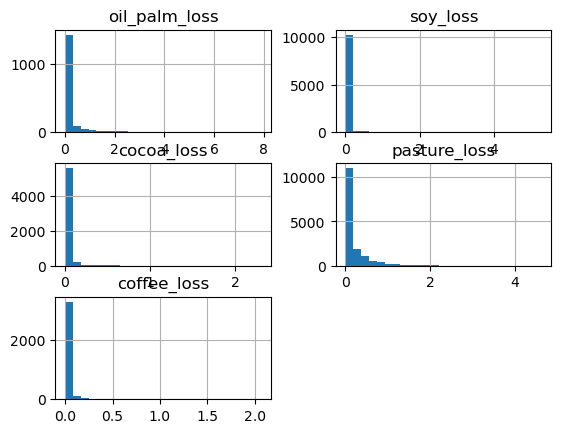

In [209]:
tropical_gdf[['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']].hist(bins=25)

In [24]:
tropical_gdf

,oil_palm_loss,soy_loss,cocoa_loss,pasture_loss,coffee_loss,area_size,country,geometry
0,NaN,0.0082883864,NaN,0.2487301853,0.0024090960,146396.8939961460,Brazil,"POLYGON ((-44.12645 -21.18245, -44.12106 -21.1..."
1,NaN,0.0000000000,NaN,0.0776740671,NaN,140719.7412152260,Brazil,"POLYGON ((-44.87632 -23.19790, -44.89290 -23.2..."
2,NaN,0.0003854866,0.0751198163,0.0000380036,NaN,83992.9297150950,Indonesia,"MULTIPOLYGON (((97.97668 1.03308, 97.97650 1.0..."
3,NaN,0.0000061206,0.0000000894,0.0000465371,NaN,73167.6073595031,Thailand,"POLYGON ((102.93129 14.17510, 102.91288 14.166..."
4,NaN,NaN,NaN,0.0012262746,NaN,10689.5468250409,Venezuela,"POLYGON ((-66.86193 10.37679, -66.86301 10.389..."
...,...,...,...,...,...,...,...,...
17995,NaN,0.0000000000,NaN,0.0787687532,NaN,14538.5049880978,Brazil,"POLYGON ((-42.66113 -22.85908, -42.67020 -22.8..."
17996,NaN,NaN,NaN,0.0933507640,NaN,165084.6984377410,Colombia,"POLYGON ((-74.25260 4.18200, -74.24680 4.19180..."
17997,NaN,NaN,0.0002460389,0.0001590508,0.0005288582,719794.5411435090,Papua New Guinea,"MULTIPOLYGON (((146.38202 -7.94054, 146.38257 ..."
17998,NaN,0.0289944809,NaN,0.4874491451,NaN,195387.2639032920,Brazil,"POLYGON ((-47.23720 -8.95945, -47.24149 -8.970..."


### Merge with labels

In [25]:

labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")
labels['geometry'] = gpd.GeoSeries.from_wkt(labels['geometry'])

labels_gdf = gpd.GeoDataFrame(labels)

In [26]:
labels_gdf

,geometry,driver,sampleid,dataset,split,country
0,POINT (-80.06997 -1.21407),cocoa,110000835,cocoa_ecuador.csv,4,Ecuador
1,POINT (-3.25273 6.05541),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire
2,POINT (-1.83249 6.04624),cocoa,30005875,cocoa.csv,1,Ghana
3,POINT (-6.44139 5.59727),cocoa,30007330,cocoa.csv,4,Côte d'Ivoire
4,POINT (-6.21232 5.62476),cocoa,30007224,cocoa.csv,4,Côte d'Ivoire
...,...,...,...,...,...,...
55298,POINT (76.66305 10.75844),urban,100002981,worldcover.csv,1,India
55299,POINT (106.68138 -6.33444),urban,100009782,worldcover.csv,1,Indonesia
55300,POINT (-35.32238 -5.74967),urban,10427227,mapbiomas.csv,2,Brazil
55301,POINT (101.54393 3.15495),urban,100004466,worldcover.csv,1,Malaysia


In [27]:
def gdf_matching(gdf_1, gdf_2, buffer=500):
    """Find which polygon intersects with each buffered point. 
    return a pandas.Series which, for every row of gdf_1, 
    contains the indices from gdf_2 that intersect with the row

    Args:
        qdf_1 (geopandas.GeoDataFrame): point gdf
        qdf_2 (geopandas.GeoDataFrame): polygon gdf


    """
    gdf_1.crs, gdf_2.crs = 4326, 4326 

    gdf_1['geometry'] = gdf_1.to_crs(3857).geometry.buffer(buffer, cap_style=3).to_crs(4326)


    # Perform spatial join between buffered points and polygons
    # 'how' is set to 'left' to keep every point even if there's no intersection
    joined = gpd.sjoin(gpd.GeoDataFrame(geometry=gdf_1['geometry']), gdf_2, how="left", op='intersects')
    
    # Group by original index from gdf_1 to aggregate the intersecting polygon indices from gdf_2
    grouped = joined.groupby(joined.index).apply(lambda x: x.index_right.dropna().astype(int).tolist())
    
    return pd.Series(grouped, index=gdf_1.index)
        


In [28]:
labels_gdf['goldman_index'] = gdf_matching(labels_gdf, tropical_gdf)

/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [75]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")


In [76]:
labels['goldman_index'] = labels_gdf['goldman_index']

In [77]:
labels.to_csv('../data/tmp/labels_55k_goldman.csv',  index=False)

In [78]:
labels

,geometry,driver,sampleid,dataset,split,country,goldman_index
0,POINT (-80.06997418635105 -1.2140731027581488),cocoa,110000835,cocoa_ecuador.csv,4,Ecuador,[13844]
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,[12051]
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,[4340]
3,POINT (-6.441386856016498 5.597266943912221),cocoa,30007330,cocoa.csv,4,Côte d'Ivoire,[4680]
4,POINT (-6.212316458566018 5.624755391523431),cocoa,30007224,cocoa.csv,4,Côte d'Ivoire,[4680]
...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,[40]
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,[]
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,[3903]
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,[9271]


In [36]:
goldman_data = pd.read_csv('../data/tmp/goldman.csv')

In [39]:
goldman_cols = ['oil_palm_loss', 'soy_loss', 'cocoa_loss', 'pasture_loss', 'coffee_loss']

In [56]:
idx = labels_gdf.iloc[14].goldman_index

In [60]:
zz = goldman_data.loc[idx, goldman_cols].values

In [58]:
labels_gdf.iloc[13].goldman_index

[8366]

In [59]:
goldman_data.loc[labels_gdf.iloc[13].goldman_index, goldman_cols].values

array([[           nan, 7.82580942e-07, 6.43175182e-01,            nan,
                   nan]])

In [67]:
np.nanmean(zz, axis=0)

/tmp/ipykernel_2191459/1115245479.py:1: RuntimeWarning: Mean of empty slice
  np.nanmean(zz, axis=0)


array([0.        ,        nan, 0.11961963, 0.31096421, 0.07404487])

In [69]:
np.nan_to_num(zz)

array([[0.        , 0.        , 0.1631108 , 0.21668821, 0.07540803],
       [0.        , 0.        , 0.07612846, 0.4052402 , 0.07268171]])